# IMDB Movie Review Sentiment Classification

**Overview.** Binary sentiment classification of movie reviews (positive vs. negative) from raw review text. Two linear models on TF-IDF features are compared with a bidirectional LSTM trained on word sequences.

**Dataset.** [IMDB Dataset of 50K Movie Reviews](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews): 50,000 labeled reviews, 25,000 positive and 25,000 negative, originally released as the [Large Movie Review Dataset](https://ai.stanford.edu/~amaas/data/sentiment/) (Maas et al., 2011).

**Approach.**
- Text cleaning: lowercasing, HTML tag removal, removal of non-letter characters, NLTK English stopword removal
- One 80/20 train/test split (`random_state=42`) shared by all models, made before any features are fitted
- Logistic Regression and Linear SVM on TF-IDF features (5,000 terms, vectorizer fit on the training split only)
- Bidirectional LSTM (Keras) on tokenized sequences (10,000-word vocabulary built from the training split, 300 tokens per review)
- Evaluation with accuracy, macro precision / recall / F1 and ROC-AUC on the 10,000-review test set

**Key results (test set).**

| Model | Accuracy | Macro-F1 | ROC-AUC |
|---|---|---|---|
| Logistic Regression | **0.8873** | **0.8872** | **0.9572** |
| Linear SVM | 0.8799 | 0.8799 | 0.9521 |
| BiLSTM | 0.8720 | 0.8719 | 0.9407 |

Logistic Regression scored highest on every metric, with Linear SVM a close second.

## Setup

The notebook runs on Google Colab, where it reads the dataset from Google Drive (`MyDrive/IMDB Dataset.csv`), or locally, where it reads `data/IMDB Dataset.csv`. The outputs shown here were produced locally on CPU (Python 3.12, scikit-learn 1.9, TensorFlow 2.21).

In [1]:
# On Google Colab the dataset is read from Google Drive, otherwise from data/
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_PATH = '/content/drive/MyDrive/IMDB Dataset.csv'
except ImportError:
    DATA_PATH = 'data/IMDB Dataset.csv'


## Data loading, exploratory statistics and preprocessing

**Dataset statistics** (review length counted in whitespace-separated words, before cleaning):
- 50,000 reviews, perfectly balanced: 25,000 positive and 25,000 negative
- Average length 231.16 words, median 173, range 4 to 2,470 words
- One positive and one negative review are printed to inspect the raw format (note the HTML `<br />` tags)

**Preprocessing:**
1. Lowercasing
2. HTML tag removal
3. Removal of all characters other than letters and whitespace (punctuation, digits)
4. Whitespace normalization
5. English stopword removal (NLTK)

Labels are encoded as positive = 1, negative = 0. The data is then split 80/20 into training and test sets (`random_state=42`, 10,000 test reviews) **before** any features are fitted. The TF-IDF vectorizer (top 5,000 terms) is fit on the training reviews only and then applied to the test reviews, so no information from the test set leaks into the features.

In [2]:
import pandas as pd
import re
from nltk.corpus import stopwords
import nltk
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))


df = pd.read_csv(DATA_PATH)

total_reviews = len(df)

class_counts = df['sentiment'].value_counts()

df['review_length'] = df['review'].apply(lambda x: len(str(x).split()))

avg_length = df['review_length'].mean()
min_length = df['review_length'].min()
max_length = df['review_length'].max()
median_length = df['review_length'].median()

print(f"Total reviews: {total_reviews}")
print(f"Class distribution:\n{class_counts}")
print(f"Average review length: {avg_length:.2f} words")
print(f"Min review length: {min_length} words")
print(f"Max review length: {max_length} words")
print(f"Median review length: {median_length} words")

print("\nExample positive review:")
print(df[df['sentiment'] == 'positive']['review'].iloc[0])
print("\nExample negative review:")
print(df[df['sentiment'] == 'negative']['review'].iloc[0])


def clean_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_review'] = df['review'].apply(clean_text)

def remove_stopwords(text):
    return ' '.join([word for word in text.split() if word not in stop_words])

df['clean_review'] = df['clean_review'].apply(remove_stopwords)

y = df['sentiment'].map({'positive': 1, 'negative': 0}).values

# Split before fitting any text features, so nothing is learned from the test reviews
train_text, test_text, y_train, y_test = train_test_split(
    df['clean_review'], y, test_size=0.2, random_state=42)

vectorizer = TfidfVectorizer(max_features=5000)
X_train = vectorizer.fit_transform(train_text)
X_test = vectorizer.transform(test_text)


Total reviews: 50000
Class distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64
Average review length: 231.16 words
Min review length: 4 words
Max review length: 2470 words
Median review length: 173.0 words

Example positive review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high o

## Logistic Regression (TF-IDF)

Logistic Regression with `max_iter=1000` and default regularization, trained on the TF-IDF training features and evaluated on the 10,000-review test set.

Accuracy: 0.8873

Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.87      0.88      4961
    Positive       0.88      0.90      0.89      5039

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



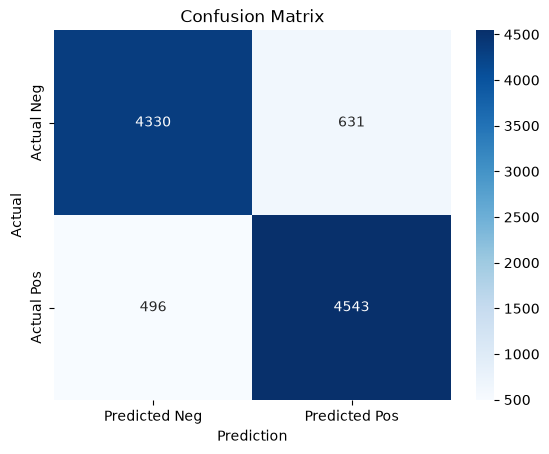

In [3]:
# Logistic Regression model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

y_pred = logreg.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Neg', 'Predicted Pos'],
            yticklabels=['Actual Neg', 'Actual Pos'])
plt.title("Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.show()

## Linear SVM (TF-IDF)

`LinearSVC` with default settings, trained on the same TF-IDF features and the same train/test split.

Accuracy: 0.8799
Macro F1 Score: 0.8799

Classification Report:
              precision    recall  f1-score   support

    Negative       0.89      0.87      0.88      4961
    Positive       0.87      0.89      0.88      5039

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



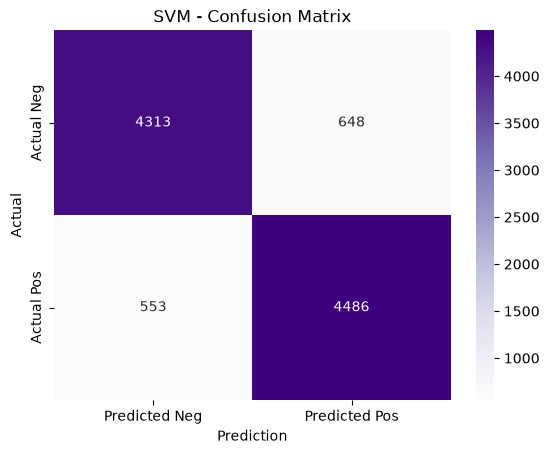

In [4]:
# Support Vector Machine classifier
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


svm_model = LinearSVC()
svm_model.fit(X_train, y_train)


y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1 Score: {macro_f1:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))


conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Predicted Neg', 'Predicted Pos'],
            yticklabels=['Actual Neg', 'Actual Pos'])
plt.title("SVM - Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.show()


## Bidirectional LSTM

The cleaned reviews are tokenized with a Keras `Tokenizer` whose vocabulary (10,000 words plus an `<OOV>` token) is built from the training reviews only, then padded or truncated to 300 tokens. The model uses the same train/test split as the linear models.

**Architecture:** Embedding (10,000 × 64) → Bidirectional LSTM (64 units) → Dropout (0.5) → Dense (64, ReLU) → Dense (1, sigmoid)

**Training:** binary cross-entropy loss, Adam optimizer, 5 epochs, batch size 128, with 20% of the training data held out for validation.

Epoch 1/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 28s 106ms/step - accuracy: 0.8073 - loss: 0.4063 - val_accuracy: 0.8831 - val_loss: 0.2879
Epoch 2/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - accuracy: 0.9112 - loss: 0.2318 - val_accuracy: 0.8809 - val_loss: 0.2939
Epoch 3/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 27s 106ms/step - accuracy: 0.9246 - loss: 0.2005 - val_accuracy: 0.8756 - val_loss: 0.3376
Epoch 4/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 28s 113ms/step - accuracy: 0.9490 - loss: 0.1443 - val_accuracy: 0.8714 - val_loss: 0.3738
Epoch 5/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 30s 119ms/step - accuracy: 0.9600 - loss: 0.1117 - val_accuracy: 0.8683 - val_loss: 0.4030
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step

BiLSTM Classification Report:
              precision    recall  f1-score   support

    Negative       0.88      0.86      0.87      4961
    Positive       0.86      0.89      0.87      5039

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weigh

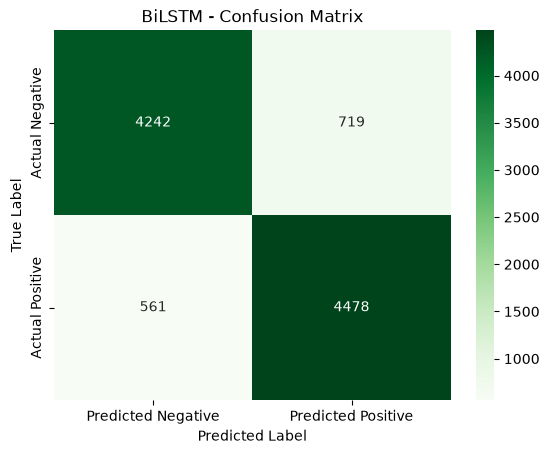

In [5]:
# BiLSTM model
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import classification_report, f1_score, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# Vocabulary is built from the training reviews only
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(train_text)

X_train_dl = pad_sequences(tokenizer.texts_to_sequences(train_text), maxlen=300)
X_test_dl = pad_sequences(tokenizer.texts_to_sequences(test_text), maxlen=300)
y_train_dl, y_test_dl = y_train, y_test


model = Sequential([
    Embedding(input_dim=10000, output_dim=64, input_length=300),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])


history = model.fit(
    X_train_dl, y_train_dl,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)


y_pred_prob = model.predict(X_test_dl)
y_pred = (y_pred_prob > 0.5).astype("int32")

print("\nBiLSTM Classification Report:")
print(classification_report(y_test_dl, y_pred, target_names=["Negative", "Positive"]))
print("Accuracy:", accuracy_score(y_test_dl, y_pred))
print("Macro F1 Score:", f1_score(y_test_dl, y_pred, average='macro'))

conf_matrix = confusion_matrix(y_test_dl, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])

plt.title("BiLSTM - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


## Evaluation and model comparison

All three models are scored on the same 10,000-review test set with accuracy, macro-averaged precision, recall and F1, and ROC-AUC. ROC-AUC uses predicted probabilities for Logistic Regression and the BiLSTM, and decision-function scores for the Linear SVM.

In [6]:
# Evaluation for LogReg, SVM, BiLSTM
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    roc_auc_score
)

def compute_metrics(y_true, y_pred, y_score=None, model_name=""):
    """Return a dict with the main evaluation metrics."""
    acc  = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    auc = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    return {
        "Model": model_name,
        "Accuracy": acc,
        "Macro-Precision": prec,
        "Macro-Recall": rec,
        "Macro-F1": f1,
        "ROC-AUC": auc
    }

metrics_list = []

# Logistic Regression
y_pred_lr   = logreg.predict(X_test)
y_score_lr  = logreg.predict_proba(X_test)[:, 1]
metrics_list.append(
    compute_metrics(y_test, y_pred_lr, y_score_lr, "Logistic Regression")
)

# SVM
y_pred_svm  = svm_model.predict(X_test)

y_score_svm = svm_model.decision_function(X_test)
metrics_list.append(
    compute_metrics(y_test, y_pred_svm, y_score_svm, "Linear SVM")
)

# BiLSTM
y_score_dl  = model.predict(X_test_dl, verbose=0).ravel()
y_pred_dl   = (y_score_dl > 0.5).astype("int32")
metrics_list.append(
    compute_metrics(y_test_dl, y_pred_dl, y_score_dl, "BiLSTM")
)


results_df = pd.DataFrame(metrics_list)


numeric_cols = ["Accuracy", "Macro-Precision", "Macro-Recall", "Macro-F1", "ROC-AUC"]
results_df[numeric_cols] = results_df[numeric_cols].astype(float)

display(results_df.style.format({col: "{:.4f}" for col in numeric_cols}))









,Model,Accuracy,Macro-Precision,Macro-Recall,Macro-F1,ROC-AUC
0,Logistic Regression,0.8873,0.8876,0.8872,0.8872,0.9572
1,Linear SVM,0.8799,0.8801,0.8798,0.8799,0.9521
2,BiLSTM,0.8720,0.8724,0.8719,0.8719,0.9407


## Comparison plots

A heat-map of all metrics, followed by one horizontal bar chart per metric (the x-axis starts at 0.80 so the differences are visible).

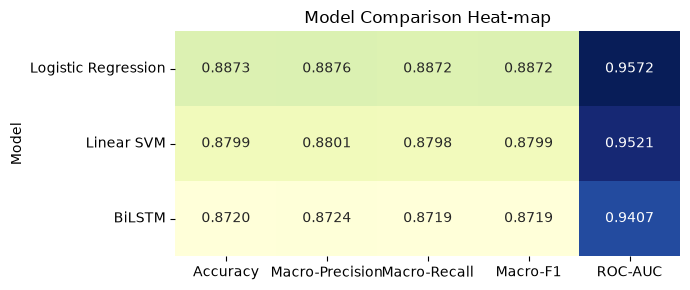

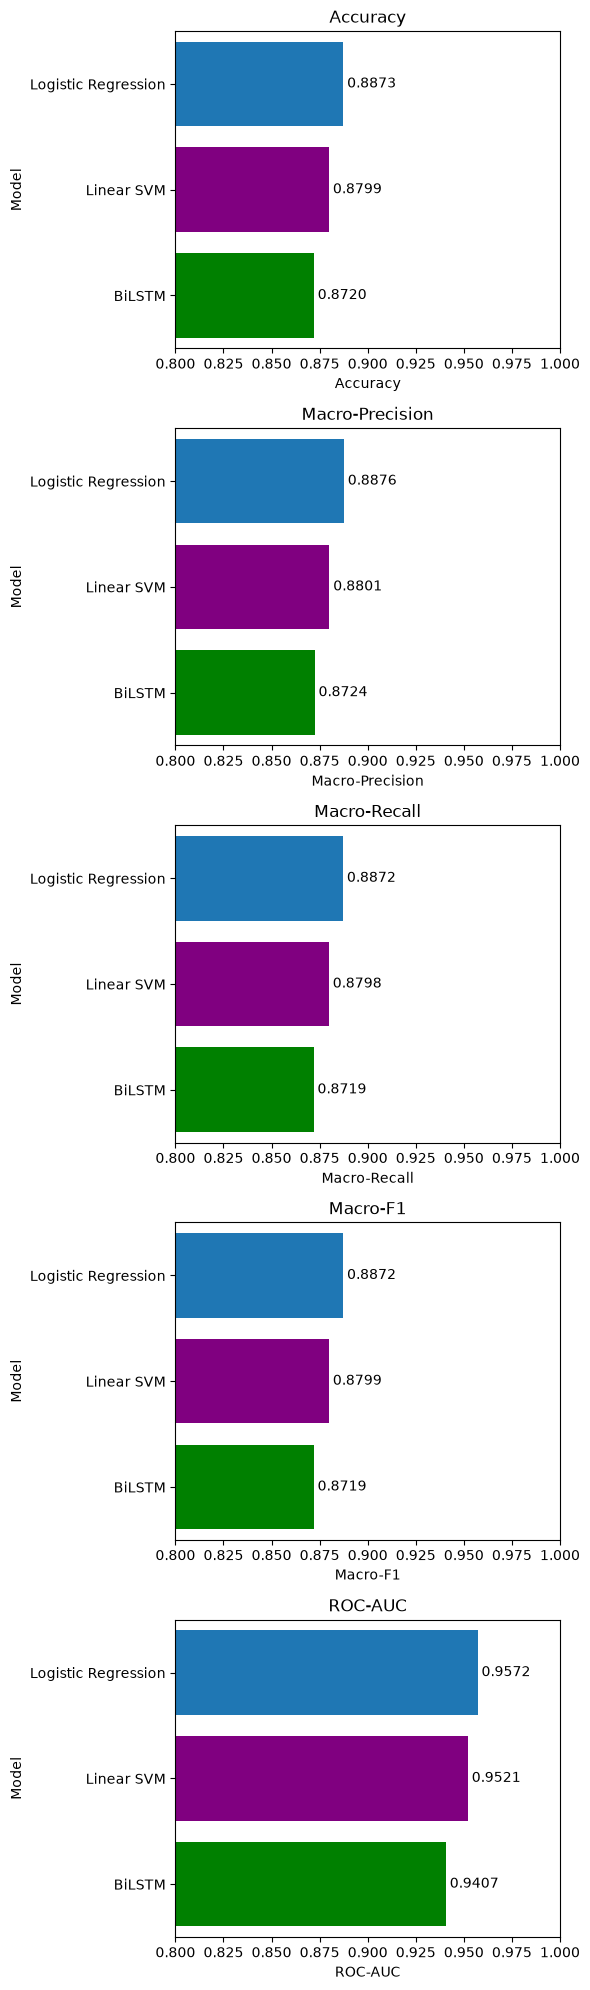

In [7]:

# HEAT-MAP

import matplotlib.pyplot as plt
import seaborn as sns

metric_cols = ["Accuracy", "Macro-Precision",
               "Macro-Recall", "Macro-F1", "ROC-AUC"]

plt.figure(figsize=(7,3))
sns.heatmap(results_df.set_index("Model")[metric_cols],
            annot=True, fmt=".4f", cmap="YlGnBu", cbar=False)
plt.title("Model Comparison Heat-map")
plt.tight_layout()
plt.show()


# HORIZONTAL BAR CHARTS with per-model colors

# Colour map: LR = blue, SVM = purple, BiLSTM = green
model_colors = {
    "Logistic Regression": "tab:blue",
    "Linear SVM":          "purple",
    "BiLSTM":              "green",
}

fig, axes = plt.subplots(len(metric_cols), 1,
                         figsize=(6, 4*len(metric_cols)),
                         sharex=False)

for i, metric in enumerate(metric_cols):
    ax = axes[i]
    data_sorted = results_df.sort_values(metric, ascending=False)


    sns.barplot(data=data_sorted,
                x=metric, y="Model",
                orient="h", ax=ax,
                color="lightgrey",
                legend=False)


    for p, model_name in zip(ax.patches, data_sorted["Model"]):
        p.set_facecolor(model_colors[model_name])

    ax.set_xlim(0.80, 1.00)
    ax.set_title(metric)


    for p in ax.patches:
        width = p.get_width()
        ax.text(width + 0.002, p.get_y() + p.get_height()/2,
                f"{width:.4f}", va="center")

plt.tight_layout()
plt.show()


## Discussion & Results

### Results

| Model | Accuracy | Macro-Precision | Macro-Recall | Macro-F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | **0.8873** | **0.8876** | **0.8872** | **0.8872** | **0.9572** |
| Linear SVM | 0.8799 | 0.8801 | 0.8798 | 0.8799 | 0.9521 |
| BiLSTM | 0.8720 | 0.8724 | 0.8719 | 0.8719 | 0.9407 |

**Overall.** Logistic Regression achieved the best performance on every metric, followed closely by Linear SVM. The differences between the three models are small.

**Ranking quality (ROC-AUC).** Logistic Regression's ROC-AUC of 0.9572 shows that it separates positive and negative reviews well across decision thresholds, i.e. it reliably ranks positive reviews above negative ones. Linear SVM is close behind at 0.9521.

**Precision and recall.** Macro-precision and macro-recall are nearly identical for each model (0.8876 and 0.8872 for Logistic Regression), so none of the models shows a significant bias toward one class. Macro-F1, which combines the two, follows the same ranking: 0.8872 for Logistic Regression, ahead of Linear SVM and the BiLSTM.

**BiLSTM.** The BiLSTM reached a ROC-AUC of 0.9407 with balanced precision and recall (macro-F1 0.8719), which shows that it captures sentiment signals from word order and context. In the training log, validation loss was lowest after the first epoch (0.2879) and rose to 0.4030 by epoch 5 while training accuracy reached 0.9600, so the network starts to overfit within the five training epochs.

### Discussion

The strong results of Logistic Regression and Linear SVM show that the TF-IDF representation captures most of the sentiment-relevant information in these reviews. The small gap between the two linear models suggests that the two sentiment classes are largely linearly separable in this feature space. Additional model complexity therefore does not automatically pay off for this kind of task, unless the features or the dataset size justify it. The BiLSTM's results still show the potential of sequence models when sentiment depends on more complex semantic relationships within the text.

### Conclusion

- With careful preprocessing (cleaning, stopword removal, TF-IDF), simple linear models are highly competitive for sentiment classification.
- Logistic Regression was the best model on every metric, closely followed by Linear SVM.
- Evaluating with several metrics (accuracy, macro precision / recall / F1, ROC-AUC) and confusion matrices gives a more complete view of model behavior than accuracy alone.